# HAM10000 Exploratory Data Analysis
### Master's thesis prototype: interpretable melanoma detection with fairness analysis

This notebook is the first phase of the project. It answers three questions with data:

1. How severe is the class imbalance problem in dermoscopy datasets?
2. Why do lesion-aware (grouped) splits matter for honest evaluation?
3. What does the skin tone story look like? First proxy signal here, full analysis planned with Fitzpatrick17k.

Data: HAM10000, 10,015 dermoscopic images across 7 diagnostic classes.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import cv2
import matplotlib.pyplot as plt
import numpy as np

from melanoma.data.metadata import class_counts, load_metadata
from melanoma.data.splits import make_splits
from melanoma.data.transforms import build_transforms
from melanoma.viz.plots import denormalize_tensor, plot_sample_grid

plt.rcParams["figure.dpi"] = 110

METADATA_CSV = PROJECT_ROOT / "data" / "raw" / "HAM10000_metadata.csv"
IMAGES_DIR = PROJECT_ROOT / "data" / "HAM10000" / "images"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "eda"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert METADATA_CSV.exists(), "Data missing. Run: python scripts/download_data.py"

frame = load_metadata(METADATA_CSV)
frame.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


## 1. Dataset overview and the imbalance problem

The single most important fact about this dataset: benign lesions dominate by an order of magnitude. A model that always predicts the majority class looks accurate while being clinically useless.

Images: 10,015
Unique lesions: 7,470
Most common vs least common class: 58 to 1
Melanoma share of all images: 11.1%


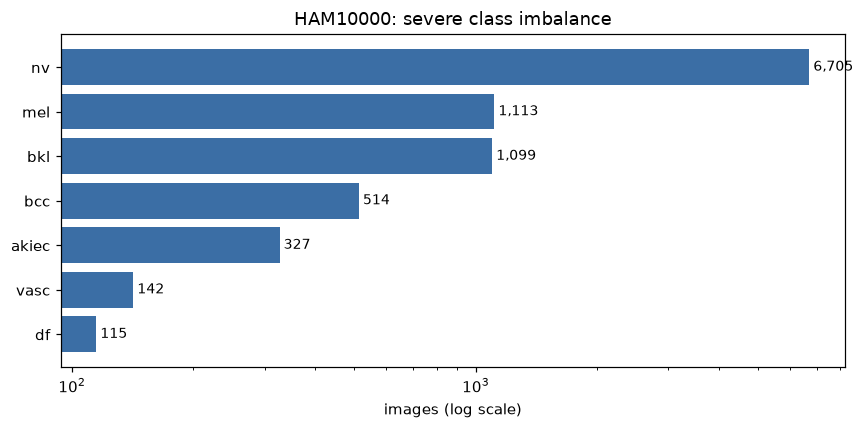

In [2]:
counts = class_counts(frame)
imbalance_ratio = counts.max() / counts.min()

print(f"Images: {len(frame):,}")
print(f"Unique lesions: {frame['lesion_id'].nunique():,}")
print(f"Most common vs least common class: {imbalance_ratio:.0f} to 1")
print(f"Melanoma share of all images: {(frame['dx'] == 'mel').mean() * 100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(counts.index, counts.values, color="#3b6ea5")
ax.set_xscale("log")
ax.set_xlabel("images (log scale)")
ax.set_title("HAM10000: severe class imbalance")
for bar, value in zip(bars, counts.values):
    ax.text(value, bar.get_y() + bar.get_height() / 2, f" {value:,}", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "class_distribution.png", bbox_inches="tight")
plt.show()

**Interpretation.** Always predicting "nevus" would give roughly 67% raw accuracy and 0% melanoma sensitivity. This is why the project trains with focal loss plus class-balanced sampling, and reports sensitivity, balanced accuracy, and AUC instead of raw accuracy.

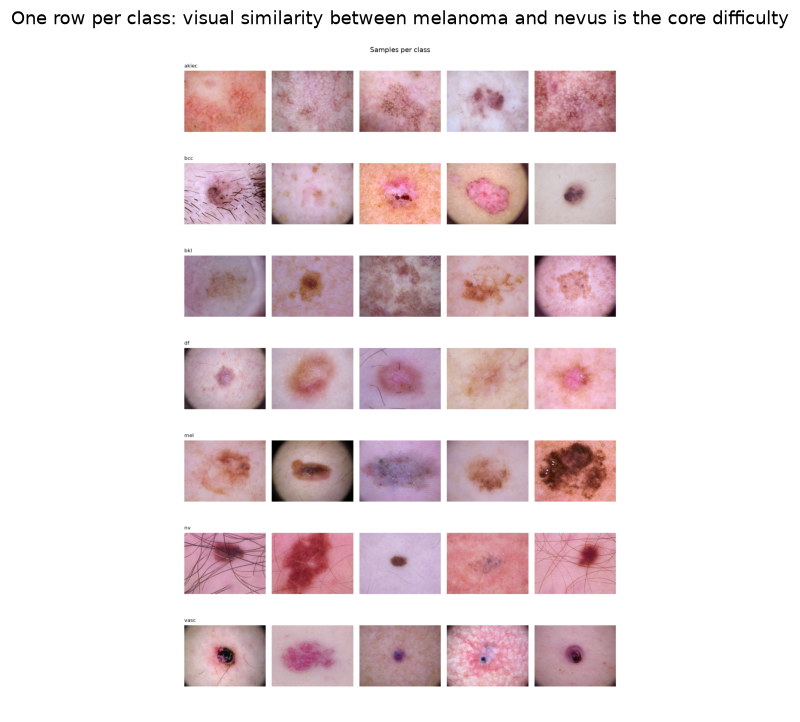

In [3]:
grid_path = plot_sample_grid(frame, IMAGES_DIR, FIGURES_DIR / "sample_grid.png", n_per_class=5)
grid_image = plt.imread(grid_path)
fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(grid_image)
ax.axis("off")
ax.set_title("One row per class: visual similarity between melanoma and nevus is the core difficulty")
plt.show()

## 2. Image properties and metadata

Practical facts that drive preprocessing decisions: image resolution spread, artifacts, and which metadata columns exist (candidates for later fairness analysis).

In [4]:
rng = np.random.default_rng(0)
sample_ids = rng.choice(frame["image_id"].values, size=200, replace=False)
widths, heights = [], []
for image_id in sample_ids:
    image = cv2.imread(str(IMAGES_DIR / f"{image_id}.jpg"))
    if image is not None:
        heights.append(image.shape[0])
        widths.append(image.shape[1])

print(f"Sampled {len(widths)} images")
print(f"Width: mean {np.mean(widths):.0f}, min {np.min(widths)}, max {np.max(widths)}")
print(f"Height: mean {np.mean(heights):.0f}, min {np.min(heights)}, max {np.max(heights)}")
print(f"\nMetadata columns: {list(frame.columns)}")
print(f"\nAge: {frame['age'].describe().round(1).to_string()}")
print(f"\nSex counts:\n{frame['sex'].value_counts().to_string()}")
print(f"\nTop localizations:\n{frame['localization'].value_counts().head(5).to_string()}")

Sampled 200 images
Width: mean 600, min 600, max 600
Height: mean 450, min 450, max 450

Metadata columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']

Age: count    9958.0
mean       51.9
std        17.0
min         0.0
25%        40.0
50%        50.0
75%        65.0
max        85.0

Sex counts:
sex
male       5406
female     4552
unknown      57

Top localizations:
localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022


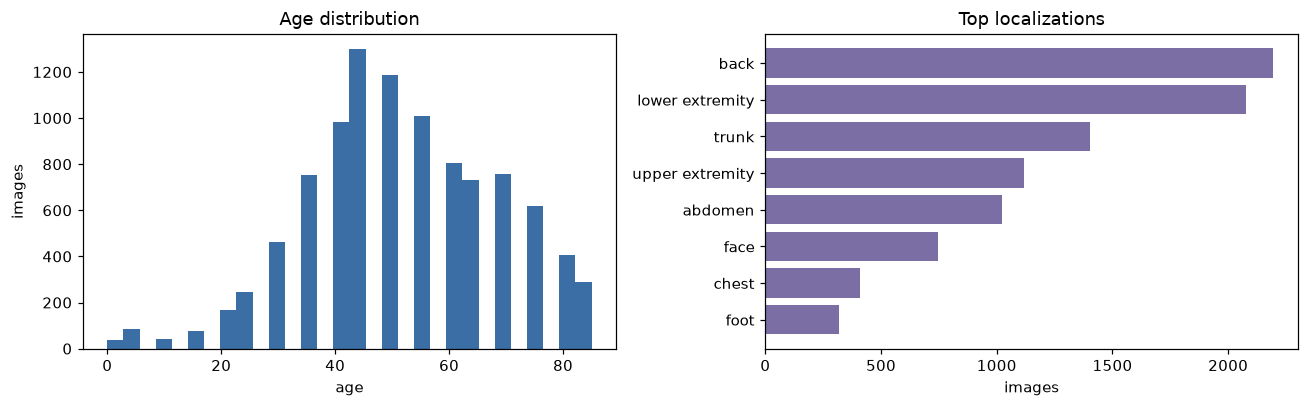

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(frame["age"].dropna(), bins=30, color="#3b6ea5")
axes[0].set_xlabel("age")
axes[0].set_ylabel("images")
axes[0].set_title("Age distribution")

top_localizations = frame["localization"].value_counts().head(8)
axes[1].barh(top_localizations.index[::-1], top_localizations.values[::-1], color="#7a6ea5")
axes[1].set_xlabel("images")
axes[1].set_title("Top localizations")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "metadata_distributions.png", bbox_inches="tight")
plt.show()

## 3. Multiple images per lesion: why random splits leak

HAM10000 contains multiple images of the same lesion. A naive random split puts images of the same lesion in both train and test, and the model can memorize the lesion rather than learn generalizable features. All splits in this project are lesion-aware.

In [6]:
images_per_lesion = frame.groupby("lesion_id").size()
share_multi = (images_per_lesion > 1).mean() * 100
print(f"Lesions with more than one image: {share_multi:.1f}%")
print(f"Maximum images for a single lesion: {images_per_lesion.max()}")

naive_sample = frame.sample(frac=0.2, random_state=0)
naive_rest = frame.drop(naive_sample.index)
leaked_lesions = set(naive_sample["lesion_id"]) & set(naive_rest["lesion_id"])
print(f"\nNaive random split leaks {len(leaked_lesions)} lesions across the boundary")

proper = make_splits(frame, seed=0)
split_sets = {name: set(part["lesion_id"]) for name, part in proper.groupby("split")}
overlap = split_sets["train"] & split_sets["test"]
print(f"Lesion-aware split overlap between train and test: {len(overlap)} lesions")
print(f"\nSplit sizes:\n{proper['split'].value_counts().to_string()}")

Lesions with more than one image: 26.2%
Maximum images for a single lesion: 6

Naive random split leaks 715 lesions across the boundary
Lesion-aware split overlap between train and test: 0 lesions

Split sizes:
split
train    7014
test     1505
val      1496


## 4. Skin tone proxy (preview only)

HAM10000 does not carry Fitzpatrick skin type labels. As a first, deliberately crude signal, we measure the luminance of the skin ring around each lesion. This is **not** a skin tone classification and no conclusions should be drawn from it beyond "public datasets skew light"; the real analysis uses tone-annotated datasets (Fitzpatrick17k and others) in Phase 3, and the known limitations of the Fitzpatrick scale will be discussed in the thesis.

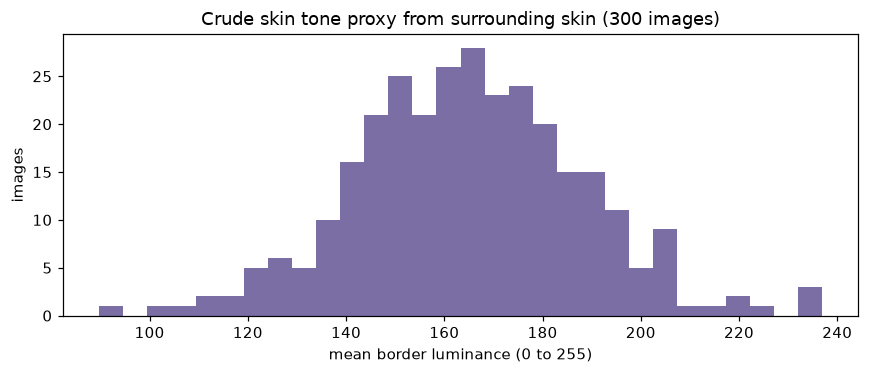

Median: 165.0 | IQR: 149.4 to 179.2
Share below luminance 90 (darker skin proxy): 0.3%


In [7]:
def border_luminance(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    ring = max(h, w) // 12
    mask = np.zeros_like(gray, dtype=bool)
    mask[:ring, :] = True
    mask[-ring:, :] = True
    mask[:, :ring] = True
    mask[:, -ring:] = True
    pixels = gray[mask & (gray > 10)]
    return float(pixels.mean()) if pixels.size else float("nan")


values = []
for image_id in frame.sample(300, random_state=1)["image_id"]:
    image = cv2.imread(str(IMAGES_DIR / f"{image_id}.jpg"))
    if image is not None:
        value = border_luminance(image)
        if not np.isnan(value):
            values.append(value)
values = np.asarray(values)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(values, bins=30, color="#7a6ea5")
ax.set_xlabel("mean border luminance (0 to 255)")
ax.set_ylabel("images")
ax.set_title("Crude skin tone proxy from surrounding skin (300 images)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "tone_proxy.png", bbox_inches="tight")
plt.show()

print(f"Median: {np.median(values):.1f} | IQR: {np.percentile(values, 25):.1f} to {np.percentile(values, 75):.1f}")
print(f"Share below luminance 90 (darker skin proxy): {(values < 90).mean() * 100:.1f}%")

## 5. Augmentation preview

What the model sees during training: geometric and photometric augmentations applied with Albumentations. The 'strong' regime (used in later experiments) simulates domain shift with harder color and affine transforms.

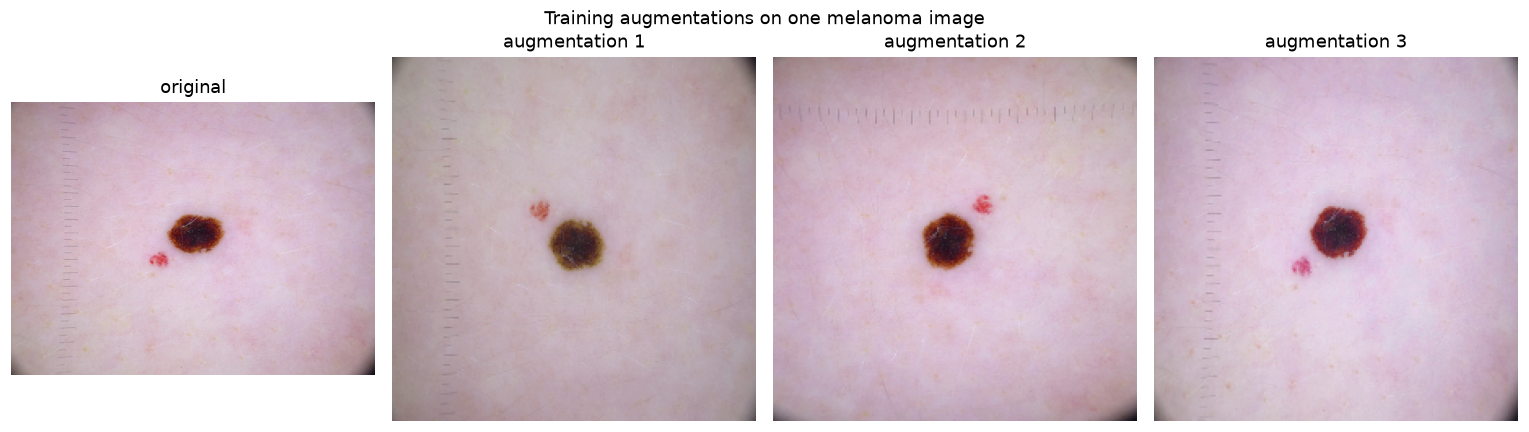

In [8]:
image_id = frame[frame["dx"] == "mel"].iloc[0]["image_id"]
melanoma_image = cv2.cvtColor(cv2.imread(str(IMAGES_DIR / f"{image_id}.jpg")), cv2.COLOR_BGR2RGB)

transform = build_transforms(224, train=True)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(melanoma_image)
axes[0].set_title("original")
for index, axis in enumerate(axes[1:], start=1):
    augmented = denormalize_tensor(transform(image=melanoma_image)["image"])
    axis.imshow(augmented)
    axis.set_title(f"augmentation {index}")
for axis in axes:
    axis.axis("off")
fig.suptitle("Training augmentations on one melanoma image")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "augmentation_preview.png", bbox_inches="tight")
plt.show()

## Takeaways and next steps

**Data findings**
- Class imbalance is roughly 58 to 1 between nevus (dominant) and dermatofibroma (rarest), and melanoma is only about 11% of images.
- About 20% of lesions have multiple images, so naive random splits leak and overstate performance.
- Resolution varies widely, justifying a fixed resize with augmentation.
- The tone proxy confirms the dataset skews light. This motivates the fairness part of the thesis.

**Next steps (per the research plan)**
1. Train the pilot grid (ResNet-50, EfficientNet-B0, ViT-S) with focal loss and class-balanced sampling, pilots on a Kaggle GPU.
2. Evaluate with sensitivity, balanced accuracy, and sensitivity at fixed specificity.
3. Quantify per skin tone group performance on Fitzpatrick17k.
4. Test whether attribution leakage (Grad-CAM mass outside the lesion) predicts bias.
5. Test mitigation strategies: tone-aware resampling, targeted augmentation, group-aware loss weighting.

All figures saved under `outputs/eda/`.